# Historico de Bitácoras Onomásticas del SEMEFO-DF
# Análisis de diagnósticos

Las [Historico de Bitácoras Onomásticas del Servicio Médico Forense del Distrito Federal (SEMEFO-DF)](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai), han sido sistematizada por la Comisión Nacional de Búsqueda (CNB). Este conjunto de datos se obtuvo a través de una solicitud de acceso a la información disponible en el Portal de Transparencia del Instituto Nacional de acceso a la Información (INAI) en noviembre de 2023 y existe una copia en el portal ciudadano _datamx_ de Codeando México.

El **SEMEFO-DF (Servicio Médico Forense Distrito Federal)** ahora [INCIFO-CdMx](https://www.incifocdmx.gob.mx/) es una institución oficial encargada de realizar autopsias y estudios forenses para esclarecer las causas de muerte, principalmente en casos de muertes violentas, sospechosas o relacionadas con hechos delictivos. Las **Bitácoras Onomásticas (BO)** son registros administrativos históricos utilizados por el SEMEFO para documentar el ingreso de cadáveres o restos humanos a sus instalaciones. Estas bitácoras contienen información detallada sobre cada ingreso, como el nombre de la persona fallecida, su edad, sexo, fecha de ingreso, institución de procedencia y diagnóstico preliminar de causa de muerte. En muchos casos, estos registros incluyen datos clave para identificar patrones históricos de mortalidad, enfermedades comunes y factores de riesgo, lo que las convierte en una fuente valiosa para estudios demográficos, epidemiológicos y de salud pública.

Podemos acceder a esta información con la [Plataforma de Transparencia](https://www.plataformadetransparencia.org.mx/Inicio) o en [datamx](https://datamx.io/dataset/ingresos-del-semefo-df-1965-1982-inai).

In [1]:
from joblib import load
import pandas as pd
from pandas.api.types import CategoricalDtype

from numpy import nan
from helper_pandas import *
from helper_networkx import *
from unidecode import unidecode
from scipy.stats import chi2_contingency

import networkx as nx
from itertools import combinations

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
pd.options.mode.chained_assignment = None 

in_file = "data_clean/HBO_clean.pkl"
with open(in_file, 'rb') as f:
     df = load(f)

#Quitar filas vacias
df = df[df['Conocido_desconocido']!='S-D']
df.tail()

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Primer_apellido,Segundo_apellido,Nombres_propios,Fecha_transcrito,Fecha_estandar,Fecha_año,Fecha_mes,Fecha_semana,...,Procedencia_transcrito,Procedencia_estandar,Procedencia_extendido,Procedencia_alcaldia,Procedencia_clasificacion,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Bitacora_ingresos,Foja_transcrito,Observaciones
ID,,,,,,,,,,,,,,,,,,,,,
BO_1982_07489,S-D,placenta,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,15a,GAM-2,Coord Territorial 2 Gustavo A Madero (Col Arag...,Gustavo A Madero,Judicial,960,3079,semefo_df_bo_1982,156,NaN
BO_1982_07490,S-D,5 dedos del pie derecho de desconocido,NaN,NaN,NaN,1982-06-05,1982-06-05,1982.0,6.0,22,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,950,3060,semefo_df_bo_1982,156,NaN
BO_1982_07491,S-D,dedo de desconocido,NaN,NaN,NaN,1982-11-19,1982-11-19,1982.0,11.0,46,...,32a,COY-2,Coord Territorial 2 Coyoacan (Col Romero de Te...,Coyoacan,Judicial,2005,6389,semefo_df_bo_1982,156,NaN
BO_1982_07492,S-D,4 dedos de desconocido,NaN,NaN,NaN,1982-11-28,1982-11-28,1982.0,11.0,47,...,27a,XO-2,Coord Territorial 2 Xochimilco (Barrio de San ...,Xochimilco,Judicial,959,6528,semefo_df_bo_1982,156,NaN
BO_1982_07493,S-D,osamenta de desconocido,NaN,NaN,NaN,1982-10-11,1982-10-11,1982.0,10.0,41,...,9a,MH-1,Coord Territorial 1 Miguel Hidalgo – Hospital ...,Miguel Hidalgo,Hospital,4193,5629,semefo_df_bo_1982,156,no se recibio necropsia. es una osamenta.


In [2]:
from matplotlib.colors import LinearSegmentedColormap

dic_color = {'Poblacion':'#0504aa', 'S-D':'#999999', 'S-D (DF)':'#d9d9d9', 'Masculino':'#377eb8', 'Masculino (DF)':'#80b1d3', 
             'Femenino':'#984ea3', 'Femenino (DF)':'#bebada', 
             'Conocido':'#4daf4a', 'Desconocido':'#dbb40c', 
             'Cadáver conocido':'#04d8b2', 'Cadáver desconocido':'#fdff52', 
             'Recién nacido':'#c875c4', 
             'Feto':'#ff7f00', 
             'Miembros':'#f781bf', 
             'Restos óseos':'#c85a53', }

gray_to_green = LinearSegmentedColormap.from_list('gray_to_green', ['#d9d9d9', '#2a7e19'])


Se llevó a cabo la siguiente selección para su análisis:
* Filtrado de restos óseos y sexo sin datos, por ser de baja frecuencia
* Clasificación con mínimo 200 ocurrencias


In [25]:
df['Diagnostico_clasificacion'].value_counts().head(50)

Diagnostico_clasificacion
Traumatismos                                                            20130
Causas externas                                                          4398
Respiratorio                                                             2385
Herida por arma de fuego                                                 2345
Digestivo                                                                1617
Sintomas, signos y hallazgos anormales                                   1438
Afecciones periodo perinatal                                             1172
Sin datos                                                                1086
Arma de fuego                                                            1019
Circulatorio                                                              956
Herida punzo cortante                                                     836
Amputación                                                                694
Infecciosas y parasitarias            

In [3]:
thr_col, thr_freq = 'Diagnostico_clasificacion', thr_ocurr
df_diag = df.copy()

# Filtrar baja frecuencia tipo y sexo
df_diag = df_diag[ df_diag['Tipo_restos']!='Restos óseos' ]
df_diag['Tipo_restos'] = df_diag['Tipo_restos'].cat.remove_unused_categories()
df_diag = df_diag[ df_diag['Sexo'].isin(['Femenino','Masculino']) ]
df_diag['Sexo'] = df_diag['Sexo'].cat.remove_unused_categories()

# Filtrar diagnósticos con baja frecuecia
top_diag = df[thr_col].value_counts()
top_diag = top_diag[top_diag>=thr_freq].index.to_list()
df_diag = df_diag[ df_diag[thr_col].isin(top_diag) ]
df_diag[thr_col] = df_diag[thr_col].astype( CategoricalDtype(categories=top_diag, ordered=True) )
# Categorias
df_diag['Diagnostico_estandar'] = df_diag['Diagnostico_estandar'].cat.remove_unused_categories()
# Resultados operacion
print(f"Diagnosticos seleccionados: {df_diag.shape[0]}/{df['Diagnostico_estandar'].notna().sum()}\n")

Diagnosticos seleccionados: 38553/40943



## Diagnósticos estandar

Frecuencia de diagnósticos estandar

In [4]:
df_cat = pd.read_excel('catalogos/cat_diag_sustitucion.xlsx')
df_cat = df_cat.groupby('Diagnostico_estandar').agg(
                        {'Diagnostico_extendido':'first',
                        'freq':'sum', 'Npartes':'first', 'Nfalta':'first'}) \
               .sort_values('freq', ascending=False)
df_cat = df_cat.drop('S-D')
df_cat.head(25)

,Diagnostico_extendido,freq,Npartes,Nfalta
Diagnostico_estandar,,,,
TM,traumatismo multiple,7525,1,0
TCE,traumatismo craneo encefalico,5992,1,0
BN,bronconeumonia,1856,1,0
CVG,congestion visceral generalizada,1329,1,0
TCT,traumatismo craneo torax,1185,1,0
HPAF,herida arma fuego,1001,1,0
HPAFC,herida arma fuego craneo,944,1,0
Dispensa,dispensa,921,1,0
Quem,quemaduras,816,1,0


Partes por diagnóstico

In [5]:
df_cat.groupby('Npartes')['freq'].agg(['sum','count'])

,sum,count
Npartes,,
1,34098,533
2,6448,1373
3,356,298
4,38,36
5,3,3


Partes sin resolver por diagnóstico

In [6]:
df_cat.groupby('Nfalta')['freq'].agg(['sum','count'])

,sum,count
Nfalta,,
0,39489,998
1,1317,1108
2,126,126
3,11,11


Gráfica resumen

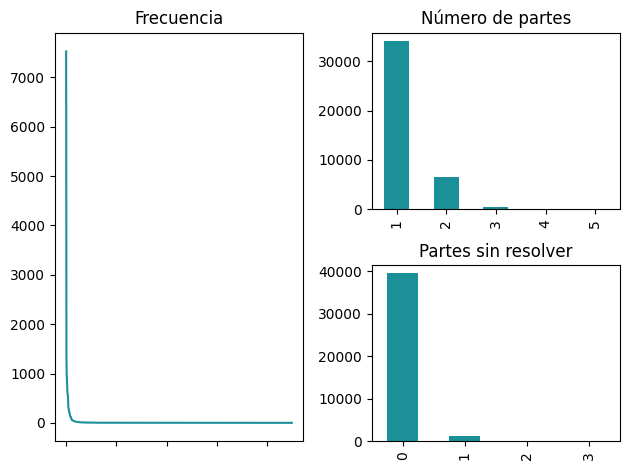

In [7]:
# Create a figure and a custom grid specification
fig = plt.figure()
gs = fig.add_gridspec(2, 2)
# Create subplots
ax1 = fig.add_subplot(gs[:, 0]) # All rows, first column
ax1 = df_cat['freq'].plot(ax=ax1, title='Frecuencia', xlabel='', color='#1c9099')
ax1.set_xticklabels([])
ax2 = fig.add_subplot(gs[0, 1]) # First row, second column
ax2 = df_cat.groupby('Npartes')['freq'].sum() \
            .plot.bar(ax=ax2, title='Número de partes', xlabel='', color='#1c9099')
ax3 = fig.add_subplot(gs[1, 1]) # Second row, second column
ax3 = df_cat.groupby('Nfalta')['freq'].sum() \
            .plot.bar(ax=ax3, title='Partes sin resolver', xlabel='', color='#1c9099')
# Adjust layout and plot
plt.tight_layout()
plt.show()

Estadísticas

Cola derecha larga

In [8]:
df_cat['freq'].describe()

count    2243.000000
mean       18.253678
std       219.285791
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max      7525.000000
Name: freq, dtype: float64

In [9]:
from scipy.stats import kurtosis
kurtosis(df_cat['freq'], fisher=True)

np.float64(859.5689285352091)

Suma cumulativa

Diagnostico_estandar
TM          0.183792
TCE         0.330142
BN          0.375473
CVG         0.407933
TCT         0.436876
HPAF        0.461324
HPAFC       0.484381
Dispensa    0.506875
Quem        0.526806
AOVA        0.546565
BN+CH       0.566104
LOC         0.582517
BN+TCE      0.598027
AQXT        0.612974
HPAFPT      0.627653
Name: freq, dtype: float64

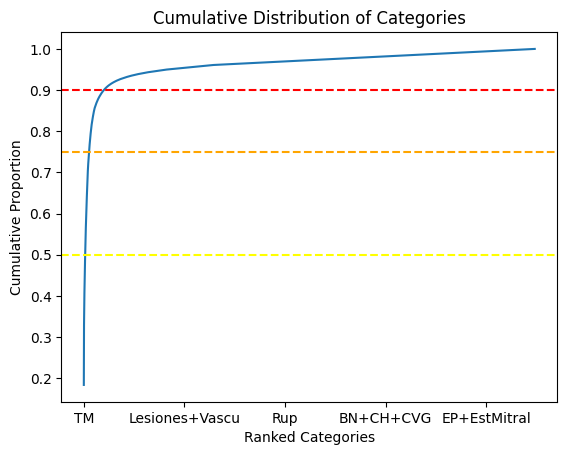

In [10]:
cum_prop = df_cat['freq'].cumsum() / df_cat['freq'].sum()
display(cum_prop.head(15))
cum_prop.plot()
plt.axhline(0.9, color='red', linestyle='--')
plt.axhline(0.75, color='orange', linestyle='--')
plt.axhline(0.5, color='yellow', linestyle='--')
plt.title("Cumulative Distribution of Categories")
plt.ylabel("Cumulative Proportion")
plt.xlabel("Ranked Categories")
plt.show()

Ajustar a ley de potencias

$$P(x)=\sigma\cdot x^{−α}$$

Calculating best minimal value for power law fit
Alpha: 1.663s: 99%
sigma:0.038
xmin: 4.0
KS distance: 0.0501


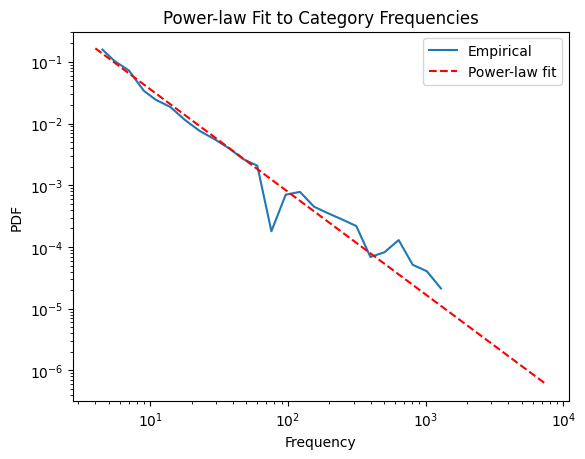

In [11]:
#! pip install powerlaw
import powerlaw

# Fit the model
fit = powerlaw.Fit(df_cat['freq'])

# Estimate alpha (exponent) and xmin
print(f"Alpha: {fit.power_law.alpha:.3f}")
print(f"sigma:{fit.power_law.sigma:.3f}")
print(f"xmin: {fit.power_law.xmin}")
print(f"KS distance: {fit.power_law.D:.4f}")

# Plot the distribution and power-law fit
fit.plot_pdf(label='Empirical')
fit.power_law.plot_pdf(color='r', linestyle='--', label='Power-law fit')
plt.legend()
plt.title("Power-law Fit to Category Frequencies")
plt.xlabel("Frequency")
plt.ylabel("PDF")
plt.show()


In [12]:
R, p = fit.distribution_compare('power_law', 'lognormal')
print(f"Likelihood ratio lognormal: {R}, p-value: {p}")
R, p = fit.distribution_compare('power_law', 'exponential')
print(f"Likelihood ratio exponential: {R}, p-value: {p}")

Likelihood ratio lognormal: -1.0612380892387543, p-value: 0.11658931265085201
Likelihood ratio exponential: 460.1506662030188, p-value: 6.519871792106589e-11


/home/esther/anaconda3/envs/SEMEFO_busqueda/lib/python3.12/site-packages/powerlaw.py:1615: RuntimeWarning: invalid value encountered in divide
  CDF = CDF/norm
'nan' in fit cumulative distribution values.
Likely underflow or overflow error: the optimal fit for this distribution gives values that are so extreme that we lack the numerical precision to calculate them.


### Red de diagnosticos

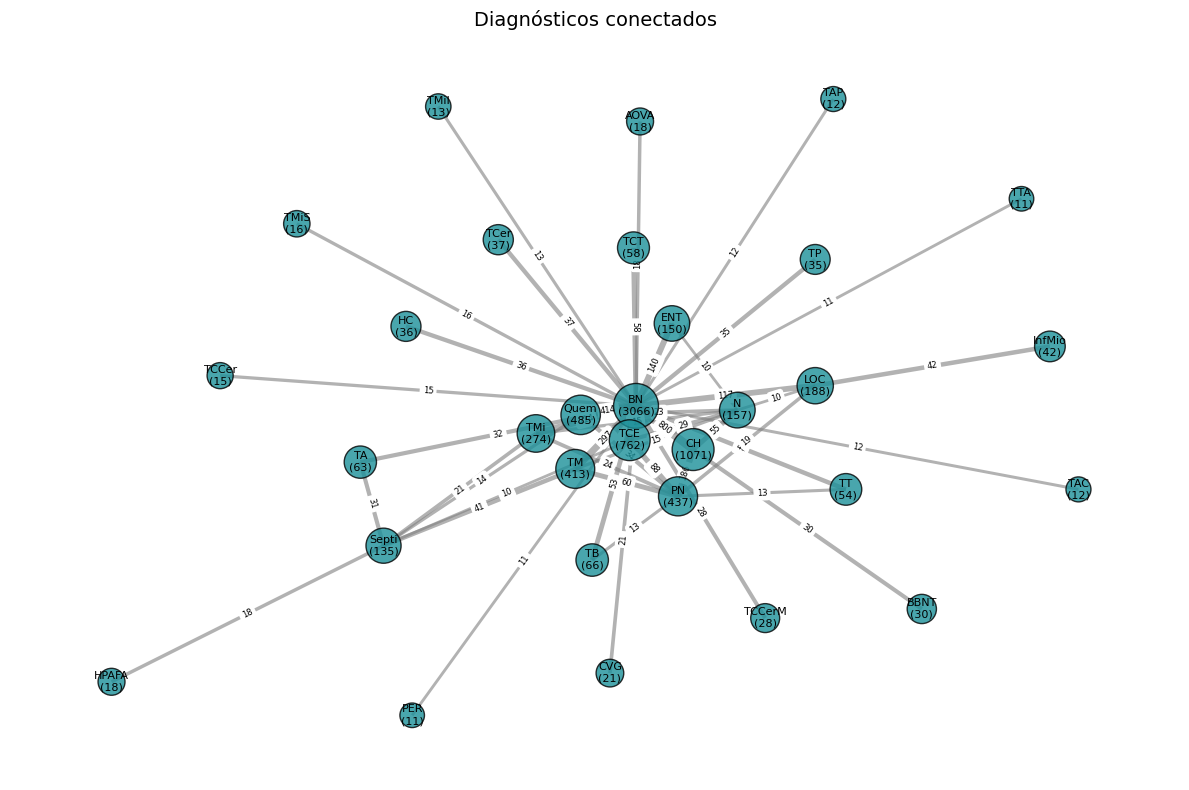

In [13]:
data = df_diag['Diagnostico_estandar'].value_counts()
data = data[data>=10]
data.to_list()
G = create_network_from_lists(data.index.to_list(), data.to_list(), sep='+')

# Obtain log10 of weight
for node in G.nodes():
    G.nodes[node]["weight_log10"] = float(np.log10( G.nodes[node]["weight"] ))
for node1, node2 in G.edges():
    G.edges[node1, node2]["weight_log10"] = float(np.log10( G.edges[node1, node2]["weight"] ))
#print_graph_output(G)

# Plot the graph
plot_weighted_graph(
                    G, plot_title="Diagnósticos conectados", 
                    node_color='#1c9099', font_size=8,
                    node_size_attribute='weight_log10', edge_width_attribute='weight_log10',
                    node_label_attribute='weight', edge_label_attribute='weight',
                    )
#export_graph_to_graphml(G, 'data_clean/HBO_diag_graph.graphml')

## Diagnósticos por clasificación


Principales diagnósticos por clasificación

In [14]:
data = df_diag.groupby('Diagnostico_clasificacion').agg(
            Freq=('Diagnostico_estandar', 'size'), 
            Top=('Diagnostico_estandar', top_values_of_series_to_string),
            )
data = data.sort_values('Freq', ascending=False).reset_index()
data

,Diagnostico_clasificacion,Freq,Top
0,Traumatismos,20120,"TM (7524), TCE (5988), TCT (1185), BN+TCE (635..."
1,Causas externas,4396,"Quem (816), AOVA (809), AXA (564), ASB (540), ..."
2,Respiratorio,2382,"BN (1854), PN (234), N (129), EP (46), BBNT (45)"
3,Herida por arma de fuego,2343,"HPAFC (943), HPAFPT (601), HPAFA (291), HPAFTA..."
4,Digestivo,1617,"BN+CH (800), CH+PN (186), CH (158), BN+ENT (14..."
5,"Sintomas, signos y hallazgos anormales",1438,"CVG (1329), BN+CVG (21), AN (5), CVG+PN (4), C..."
6,Afecciones periodo perinatal,1110,"ANEN (563), EXPSM (498), FCPN (27), Anencefali..."
7,Sin datos,1054,"Dispensa (919), Indet (64), NoCopia (43), nan ..."
8,Arma de fuego,1019,"HPAF (1001), HPAF+Septi (5), BN+HPAF (4), HPAF..."
9,Circulatorio,956,"LOC (672), BN+LOC (117), InfMio+LOC (42), LOC+..."


## Diagnóstico por tipo y sexo

Tipo_restos                            Cadáver conocido                  \
Sexo                                           Femenino       Masculino   
Diagnostico_clasificacion                                                 
Traumatismos                               4029 (55.8%)  13170 (55.91%)   
Causas externas                           1096 (15.18%)   2764 (11.73%)   
Respiratorio                                504 (6.98%)    1009 (4.28%)   
Herida por arma de fuego                    229 (3.17%)    1938 (8.23%)   
Digestivo                                   183 (2.53%)     724 (3.07%)   
Sintomas, signos y hallazgos anormales       455 (6.3%)     776 (3.29%)   
Afecciones periodo perinatal                  5 (0.07%)       9 (0.04%)   
Sin datos                                   281 (3.89%)     698 (2.96%)   
Arma de fuego                                71 (0.98%)     859 (3.65%)   
Circulatorio                                186 (2.58%)     616 (2.62%)   
Herida punzo cortante                        55 (0.76%)     680 (2.89%)   
Amputación                                    3 (0.04%)      13 (0.06%)   
Infecciosas y parasitarias                    72 (1.0%)     174 (0.74%)   
Nervioso                                     39 (0.54%)      52 (0.22%)   
Causas externas + Traumatismos               12 (0.17%)      72 (0.31%)   

Tipo_restos                            Cadáver desconocido                 \
Sexo                                              Femenino      Masculino   
Diagnostico_clasificacion                                                   
Traumatismos                                  357 (48.64%)  2472 (49.33%)   
Causas externas                                93 (12.67%)    360 (7.18%)   
Respiratorio                                   113 (15.4%)   711 (14.19%)   
Herida por arma de fuego                         11 (1.5%)    164 (3.27%)   
Digestivo                                        69 (9.4%)   628 (12.53%)   
Sintomas, signos y hallazgos anormales          30 (4.09%)    173 (3.45%)   
Afecciones periodo perinatal                    16 (2.18%)      25 (0.5%)   
Sin datos                                        7 (0.95%)     21 (0.42%)   
Arma de fuego                                    11 (1.5%)     72 (1.44%)   
Circulatorio                                    17 (2.32%)    132 (2.63%)   
Herida punzo cortante                            2 (0.27%)     97 (1.94%)   
Amputación                                                      1 (0.02%)   
Infecciosas y parasitarias                       7 (0.95%)    133 (2.65%)   
Nervioso                                         1 (0.14%)     12 (0.24%)   
Causas externas + Traumatismos                                  10 (0.2%)   

Tipo_restos                            Recién nacido               \
Sexo                                        Femenino    Masculino   
Diagnostico_clasificacion                                           
Traumatismos                             11 (12.36%)  16 (14.68%)   
Causas externas                          15 (16.85%)  18 (16.51%)   
Respiratorio                             11 (12.36%)  21 (19.27%)   
Herida por arma de fuego                                1 (0.92%)   
Digestivo                                  3 (3.37%)    7 (6.42%)   
Sintomas, signos y hallazgos anormales     1 (1.12%)    1 (0.92%)   
Afecciones periodo perinatal             44 (49.44%)  37 (33.94%)   
Sin datos                                  1 (1.12%)    2 (1.83%)   
Arma de fuego                                                       
Circulatorio                                            1 (0.92%)   
Herida punzo cortante                                   2 (1.83%)   
Amputación                                                          
Infecciosas y parasitarias                                          
Nervioso                                                1 (0.92%)   
Causas externas + Traumatismos             3 (3.37%)    2 (1.83%)   

Tipo_restos        

Text(0.5, 1.0, 'Ingresos por diagnóstico, tipo restos y sexo')

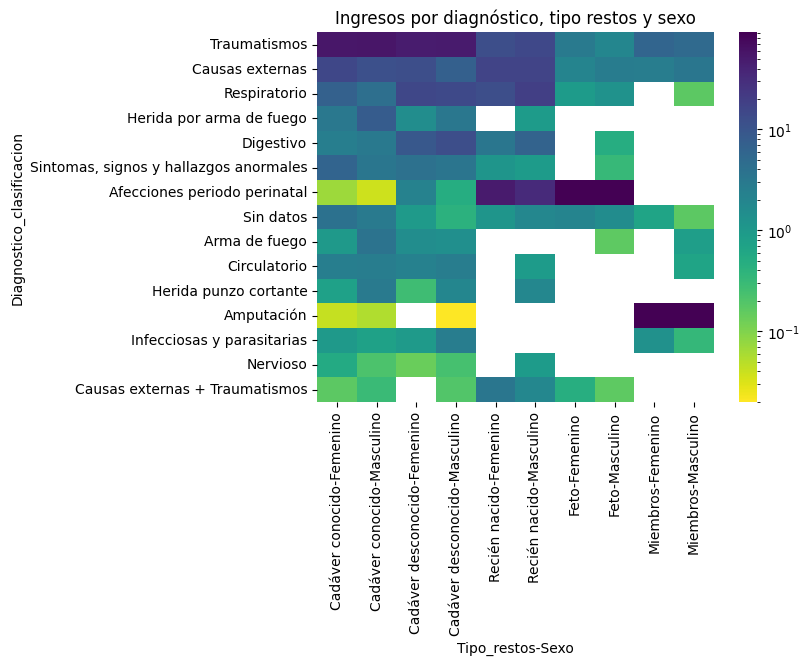

In [15]:
data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns=['Tipo_restos','Sexo'], values='Diagnostico_estandar', aggfunc='count')
data_per = (data/data.sum()*100).replace(0,nan)
data_annot = (data.astype(str) + " (" + data_per.round(2).astype(str) + "%)").replace('0 (nan%)','')
display( data_annot )
# Plot
log_norm = LogNorm(vmin=data_per.min().min(), vmax=data_per.max().max())
plt.figure()
sns.heatmap(data_per, norm=log_norm, cmap='viridis_r')
plt.title('Ingresos por diagnóstico, tipo restos y sexo')

Revisando diagnósticos con discrepancia de género

In [16]:
col_tran = [c for c in df_diag.columns if 'transcrito' in c]
df_diag.loc[(df_diag['Diagnostico_clasificacion']=='Embarazo, parto y puerperio')&(df_diag['Sexo']=='Masculino'), col_tran]

,Numero_progresivo_transcrito,Nombre_completo_transcrito,Fecha_transcrito,Edad_transcrito,Diagnostico_transcrito,Procedencia_transcrito,Numero_acta_transcrito,Expediente_SEMEFO_transcrito,Foja_transcrito
ID,,,,,,,,,


Principales diagnósticos por tipo y sexo

In [17]:
top_ = lambda s: top_values_of_series_to_string(s,thr_min=10)
data = df_diag.pivot_table(
    index='Diagnostico_clasificacion',
    columns=['Tipo_restos','Sexo'],
    values='Diagnostico_estandar',
    aggfunc=top_,
    
)
top_diag = df_diag['Diagnostico_clasificacion'].value_counts()
data = pd.concat([top_diag,data,], axis=1).sort_values('count', ascending=False)
data

,count,"(Cadáver conocido, Femenino)","(Cadáver conocido, Masculino)","(Cadáver desconocido, Femenino)","(Cadáver desconocido, Masculino)","(Recién nacido, Femenino)","(Recién nacido, Masculino)","(Feto, Femenino)","(Feto, Masculino)","(Miembros, Femenino)","(Miembros, Masculino)"
Diagnostico_clasificacion,,,,,,,,,,,
Traumatismos,20120,"TM (1542), TCE (1098), TCT (248), BN+TMi (98),...","TM (4545), TCE (4090), TCT (781), BN+TCE (495)...","TM (202), TCE (81), TCT (15)","TM (1224), TCE (693), TCT (141), BN+TCE (47), ...",NaN,NaN,NaN,NaN,NaN,TMi (26)
Causas externas,4396,"Quem (257), HC (185), AOVA (165), BN+Quem (140...","AOVA (513), Quem (477), AXA (448), ASB (354), ...","Quem (19), AOVA (17), AE (16), ASB (11), HC (11)","AOVA (107), ASB (69), Quem (57), AXA (33), HC ...",NaN,AE (10),NaN,NaN,NaN,NaN
Respiratorio,2382,"BN (400), PN (32), N (28), EP (14), BBNT (11)","BN (747), PN (105), N (70), EP (29), InfPul (22)",BN (98),"BN (576), PN (90), N (26), BBNT (11)",BN (10),BN (19),NaN,NaN,NaN,NaN
Herida por arma de fuego,2343,"HPAFC (116), HPAFPT (48), HPAFA (31), HPAFTA (17)","HPAFC (752), HPAFPT (504), HPAFA (245), HPAFTA...",NaN,"HPAFC (68), HPAFPT (48), HPAFA (14), HPAFT (13...",NaN,NaN,NaN,NaN,NaN,NaN
Digestivo,1617,"BN+CH (54), BN+ENT (34), CH (22), CH+PN (12), ...","BN+CH (320), CH+PN (84), CH (71), BN+ENT (59),...","BN+CH (39), BN+ENT (17)","BN+CH (386), CH+PN (86), CH (62), BN+ENT (22),...",NaN,NaN,NaN,NaN,NaN,NaN
"Sintomas, signos y hallazgos anormales",1438,"CVG (412), BN+CVG (10)",CVG (724),CVG (28),CVG (163),NaN,NaN,NaN,NaN,NaN,NaN
Afecciones periodo perinatal,1110,NaN,NaN,NaN,ANEN (16),ANEN (40),ANEN (35),"ANEN (196), EXPSM (186), FCPN (11)","EXPSM (304), ANEN (257)",NaN,NaN
Sin datos,1054,Dispensa (265),"Dispensa (653), NoCopia (30), nan (14), Indet ...",NaN,Indet (15),NaN,NaN,NaN,NaN,NaN,NaN
Arma de fuego,1019,HPAF (69),HPAF (845),HPAF (11),HPAF (72),NaN,NaN,NaN,NaN,NaN,NaN


### Chi-square tests

Suposiciones
* Independencia
* Categórico
* No baja frecuencia

Sexo vs tipo: p<= 0.05 rechazamos independencia -> variables dependientes

In [18]:
data = df_diag.pivot_table(index='Tipo_restos',columns='Sexo', aggfunc='size')
data

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid.where(np.abs(resid) > thr_resid)

Chi-square statistic: 599.7084920875366
Degrees of freedom: 4
P-value: 1.7918915155582914e-128


Sexo,Femenino,Masculino
Tipo_restos,,
Cadáver conocido,NaN,NaN
Cadáver desconocido,-15.412519,8.280774
Recién nacido,6.704028,NaN
Feto,12.847524,-6.902664
Miembros,NaN,NaN


Sexo vs diagnóstico: p<= 0.05 rechazamos independencia -> variables dependientes

In [19]:
data = df_diag.pivot_table(index='Diagnostico_clasificacion',columns='Sexo', aggfunc='size')
data

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid.where(np.abs(resid) > thr_resid)

Chi-square statistic: 971.2983123907994
Degrees of freedom: 14
P-value: 2.2451343419831442e-198


Sexo,Femenino,Masculino
Diagnostico_clasificacion,,
Traumatismos,NaN,NaN
Causas externas,7.402158,NaN
Respiratorio,NaN,NaN
Herida por arma de fuego,-12.433324,6.680125
Digestivo,-5.633350,NaN
"Sintomas, signos y hallazgos anormales",9.131200,NaN
Afecciones periodo perinatal,13.720845,-7.371878
Sin datos,NaN,NaN
Arma de fuego,-9.680759,5.201238


Tipo vs diagnóstico: p<= 0.05 rechazamos independencia -> variables dependientes

Se ignoran grupos de baja frecuencia

In [20]:
data = df_diag.pivot_table(index='Diagnostico_clasificacion',columns='Tipo_restos', aggfunc='size')
data = data.drop('Amputación').drop(['Recién nacido','Feto','Miembros'], axis=1)
data

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.09f}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid.where(np.abs(resid) > thr_resid)

Chi-square statistic: 2306.744814203578
Degrees of freedom: 13
P-value: 0.000000000


Tipo_restos,Cadáver conocido,Cadáver desconocido
Diagnostico_clasificacion,,
Traumatismos,NaN,-5.716326
Causas externas,NaN,-8.650962
Respiratorio,-10.285553,23.809358
Herida por arma de fuego,NaN,-10.073435
Digestivo,-12.096444,28.001273
"Sintomas, signos y hallazgos anormales",NaN,NaN
Afecciones periodo perinatal,NaN,10.999436
Sin datos,NaN,-10.513020
Arma de fuego,NaN,-6.046204


In [21]:
data = df_diag.pivot_table(index='Diagnostico_clasificacion',columns='Tipo_restos', aggfunc='size')
data

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(data)
print(f"Chi-square statistic: {chi2}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.09f}")

# visualize residuals
thr_resid = 5
resid = (data.values - expected) / np.sqrt(expected)
resid = pd.DataFrame(resid, index=data.index, columns=data.columns)
resid.where(np.abs(resid) > thr_resid)

Chi-square statistic: 67707.94328352239
Degrees of freedom: 56
P-value: 0.000000000


Tipo_restos,Cadáver conocido,Cadáver desconocido,Recién nacido,Feto,Miembros
Diagnostico_clasificacion,,,,,
Traumatismos,8.895756,NaN,-7.509125,-22.515009,-17.762236
Causas externas,5.882927,-7.895197,NaN,-8.660437,-6.652369
Respiratorio,-8.933397,24.895879,5.651407,-6.632459,-6.660359
Herida por arma de fuego,6.830176,-9.319778,NaN,-8.045108,-6.751304
Digestivo,-10.701798,29.378771,NaN,-6.234580,-5.608627
"Sintomas, signos y hallazgos anormales",NaN,NaN,NaN,-5.985353,-5.289090
Afecciones periodo perinatal,-29.306251,-9.673166,31.537394,170.356878,NaN
Sin datos,5.448654,-10.298259,NaN,NaN,NaN
Arma de fuego,NaN,-5.587038,NaN,-5.117098,NaN


## Diagnóstico por grupo de edad

Edad_grupo,"[0, 1)","[1, 5)","[5, 10)","[10, 15)","[15, 20)","[20, 25)","[25, 30)","[30, 35)","[35, 40)","[40, 45)","[45, 50)","[50, 55)","[55, 60)","[60, 65)","[65, 70)","[70, 75)","[75, 80)","[80, 85)","[85, 110)"
Diagnostico_clasificacion,,,,,,,,,,,,,,,,,,,
Traumatismos,236 (10.03%),871 (47.08%),1019 (75.43%),817 (69.06%),1223 (52.62%),1877 (51.84%),2036 (55.95%),1542 (53.32%),1661 (55.39%),1372 (52.95%),1378 (54.68%),1257 (56.75%),916 (54.72%),1007 (57.31%),882 (58.14%),821 (56.46%),594 (62.33%),304 (61.29%),263 (63.37%)
Causas externas,359 (15.25%),667 (36.05%),173 (12.81%),185 (15.64%),321 (13.81%),401 (11.07%),342 (9.4%),315 (10.89%),290 (9.67%),244 (9.42%),227 (9.01%),198 (8.94%),151 (9.02%),122 (6.94%),119 (7.84%),105 (7.22%),87 (9.13%),24 (4.84%),41 (9.88%)
Respiratorio,364 (15.46%),94 (5.08%),18 (1.33%),29 (2.45%),37 (1.59%),64 (1.77%),87 (2.39%),123 (4.25%),169 (5.64%),220 (8.49%),213 (8.45%),189 (8.53%),130 (7.77%),171 (9.73%),127 (8.37%),151 (10.39%),84 (8.81%),68 (13.71%),40 (9.64%)
Herida por arma de fuego,6 (0.25%),19 (1.03%),31 (2.29%),45 (3.8%),268 (11.53%),478 (13.2%),434 (11.93%),301 (10.41%),222 (7.4%),150 (5.79%),142 (5.63%),60 (2.71%),57 (3.41%),35 (1.99%),36 (2.37%),35 (2.41%),14 (1.47%),6 (1.21%),2 (0.48%)
Digestivo,155 (6.58%),32 (1.73%),10 (0.74%),2 (0.17%),13 (0.56%),28 (0.77%),55 (1.51%),115 (3.98%),205 (6.84%),225 (8.68%),191 (7.58%),164 (7.4%),114 (6.81%),108 (6.15%),73 (4.81%),73 (5.02%),27 (2.83%),19 (3.83%),8 (1.93%)
"Sintomas, signos y hallazgos anormales",54 (2.29%),92 (4.97%),29 (2.15%),35 (2.96%),131 (5.64%),166 (4.58%),147 (4.04%),122 (4.22%),129 (4.3%),111 (4.28%),103 (4.09%),80 (3.61%),66 (3.94%),60 (3.41%),43 (2.83%),45 (3.09%),16 (1.68%),2 (0.4%),5 (1.2%)
Afecciones periodo perinatal,1081 (45.92%),,16 (1.18%),1 (0.08%),1 (0.04%),,,,,,1 (0.04%),,,,,7 (0.48%),,,
Sin datos,41 (1.74%),46 (2.49%),28 (2.07%),21 (1.78%),67 (2.88%),80 (2.21%),72 (1.98%),50 (1.73%),27 (0.9%),36 (1.39%),43 (1.71%),44 (1.99%),54 (3.23%),56 (3.19%),53 (3.49%),55 (3.78%),37 (3.88%),21 (4.23%),19 (4.58%)
Arma de fuego,3 (0.13%),3 (0.16%),6 (0.44%),14 (1.18%),98 (4.22%),234 (6.46%),209 (5.74%),130 (4.5%),106 (3.53%),63 (2.43%),42 (1.67%),34 (1.53%),25 (1.49%),15 (0.85%),16 (1.05%),8 (0.55%),4 (0.42%),3 (0.6%),2 (0.48%)


Text(0.5, 1.0, 'Ingresos por diagnóstico y grupo de edad')

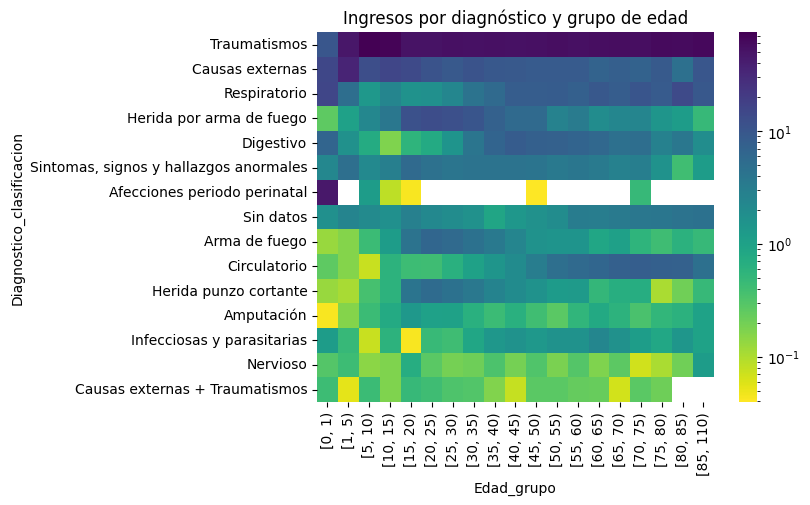

In [22]:
data = df_diag.pivot_table(index='Diagnostico_clasificacion', columns='Edad_grupo', values='Diagnostico_estandar', aggfunc='count')
data_per = (data/data.sum()*100).replace(0,nan)
data_annot = (data.astype(str) + " (" + data_per.round(2).astype(str) + "%)").replace('0 (nan%)','')
display( data_annot )
# Plot
log_norm = LogNorm(vmin=data_per.min().min(), vmax=data_per.max().max())
plt.figure()
sns.heatmap(data_per, norm=log_norm, cmap='viridis_r')
plt.title('Ingresos por diagnóstico y grupo de edad')

Principales diagnósticos por clasificación

In [23]:
top_ = lambda s: top_values_of_series_to_string(s,thr_min=10)
data = df_diag.pivot_table(
    index='Diagnostico_clasificacion',
    columns='Edad_grupo',
    values='Diagnostico_estandar',
    aggfunc=top_,
    
)
top_diag = df_diag['Diagnostico_clasificacion'].value_counts()
data = pd.concat([top_diag,data,], axis=1).sort_values('count', ascending=False)
data

,count,"[0, 1)","[1, 5)","[5, 10)","[10, 15)","[15, 20)","[20, 25)","[25, 30)","[30, 35)","[35, 40)","[40, 45)","[45, 50)","[50, 55)","[55, 60)","[60, 65)","[65, 70)","[70, 75)","[75, 80)","[80, 85)","[85, 110)"
Diagnostico_clasificacion,,,,,,,,,,,,,,,,,,,,
Traumatismos,20120,"TCE (154), TM (28), BN+TCE (10)","TCE (320), TM (276), TCT (52), TTA (34), TAC (31)","TM (370), TCE (342), TCT (61), TAC (32), TTA (30)","TM (323), TCE (256), TCT (46), TAC (25), TTA (23)","TCE (429), TM (424), TCT (69), BN+TCE (25), TT...","TM (706), TCE (591), TCT (92), BN+TCE (57), TT...","TM (842), TCE (603), TCT (88), TTA (63), BN+TC...","TM (630), TCE (436), TCT (85), TTA (45), BN+TC...","TM (672), TCE (459), TCT (92), BN+TCE (49), TT...","TM (556), TCE (406), TCT (77), BN+TCE (43), TT...","TM (527), TCE (425), TCT (86), BN+TCE (41), TT...","TM (463), TCE (361), TCT (80), BN+TCE (51), TT...","TM (344), TCE (270), TCT (77), BN+TCE (29), TT...","TM (384), TCE (267), TCT (66), BN+TM (29), BN+...","TM (317), TCE (211), TCT (60), BN+TCE (40), TT...","TM (292), TCE (200), TCT (65), BN+TCE (48), BN...","TM (204), TCE (124), TCT (39), BN+TCE (30), BN...","TM (89), TCE (72), TCT (26), BN+TMi (24), BN+T...","TM (68), TCE (57), BN+TMi (25), TCT (16), BN+T..."
Causas externas,4396,"AOVA (152), Quem (66), AE (24), BN+Quem (23), ...","Quem (211), ASB (156), BN+Quem (155), AOVA (67...","Quem (47), ASB (33), BN+Quem (29), AOVA (25)","ASB (46), AXA (30), Quem (27), AOVA (22), BN+Q...","AXA (67), ASB (58), AOVA (47), Quem (40), Elec...","AXA (120), ASB (62), Quem (57), AOVA (34), BN+...","AXA (87), Quem (78), ASB (39), AOVA (37), Elec...","Quem (56), AXA (54), AOVA (49), HC (30), ASB (28)","AOVA (65), AXA (41), Quem (37), ASB (34), HC (32)","AOVA (55), AXA (40), Quem (37), HC (33), BN+Qu...","AOVA (70), HC (40), Quem (30), AXA (20), ASB (12)","AOVA (57), HC (41), AXA (28), Quem (12), ASB (11)","AOVA (42), HC (32), Quem (21), AXA (19)","AOVA (32), HC (31), Quem (21), AXA (10)","HC (36), AOVA (22), Quem (19), AXA (13)","HC (36), Quem (21), AOVA (12)","HC (26), Quem (20), AOVA (13)",NaN,HC (13)
Respiratorio,2382,"BN (333), N (13)",BN (80),BN (15),BN (19),BN (21),BN (44),BN (60),"BN (96), PN (17)","BN (123), PN (28)","BN (158), PN (31), N (18)","BN (175), PN (14), N (13)","BN (148), PN (22), N (11)","BN (90), PN (16)","BN (122), PN (24), N (11)","BN (94), PN (18)","BN (119), PN (16)",BN (66),BN (54),BN (34)
Herida por arma de fuego,2343,NaN,HPAFC (12),HPAFC (19),"HPAFC (25), HPAFPT (14)","HPAFC (100), HPAFPT (84), HPAFA (34), HPAFTA (...","HPAFC (173), HPAFPT (142), HPAFA (70), HPAFTA ...","HPAFC (166), HPAFPT (114), HPAFA (50), HPAFTA ...","HPAFC (129), HPAFPT (62), HPAFTA (35), HPAFA (...","HPAFC (79), HPAFPT (58), HPAFTA (30), HPAFA (2...","HPAFC (57), HPAFPT (37), HPAFA (23), HPAFTA (1...","HPAFC (52), HPAFPT (33), HPAFA (29), HPAFTA (15)","HPAFC (32), HPAFPT (11)","HPAFC (26), HPAFPT (10)","HPAFC (14), HPAFPT (10)",HPAFC (21),HPAFC (23),NaN,NaN,NaN
Digestivo,1617,"BN+ENT (114), ENT (15)",BN+ENT (16),NaN,NaN,NaN,BN+CH (14),BN+CH (18),"BN+CH (55), CH (18), CH+PN (16), Pancrea (10)","BN+CH (105), CH+PN (28), CH (25), CH+N (12)","BN+CH (127), CH+PN (31), CH (31)","BN+CH (112), CH+PN (31), CH (21)","BN+CH (103), CH (22), CH+PN (12)","BN+CH (70), CH+PN (17), CH (11)","BN+CH (78), CH+PN (14)","BN+CH (39), CH+PN (10)","BN+CH (42), CH+PN (13)",BN+CH (12),NaN,NaN
"Sintomas, signos y hallazgos anormales",1438,CVG (49),CVG (86),CVG (26),CVG (32),CVG (128),CVG (152),CVG (135),CVG (111),CVG (120),CVG (102),CVG (97),CVG (76),CVG (62),CVG (53),CVG (39),CVG (38),CVG (15),NaN,NaN
Afecciones periodo perinatal,1110,"ANEN (546), EXPSM (493), FCPN (25)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sin datos,1054,"Indet (27), Dispensa (13)",Dispensa (45),Dispensa (25),Dispensa (20),Dispensa (62),Dispensa (70),Dispensa (59),Dispensa (44),Dispensa (21),Dispensa (31),Dispensa (35),Dispensa (40),Dispensa (52),Dispensa (54),Dispensa (52),Dispensa (50),Dispensa (34),

## Red palabras por clasificación

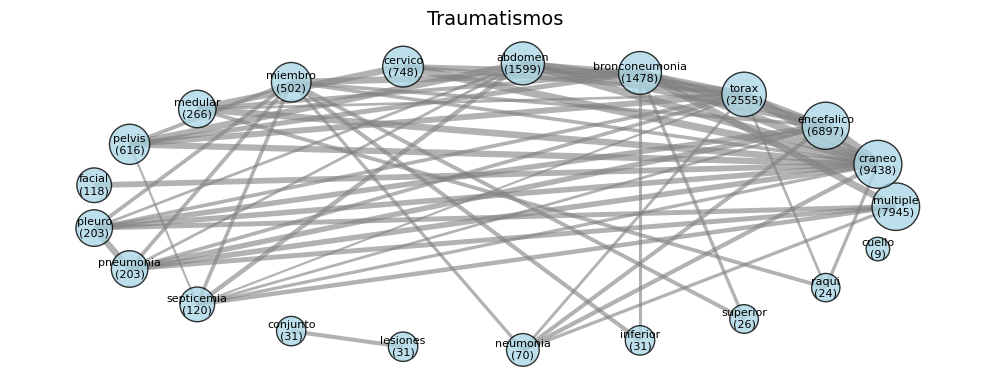

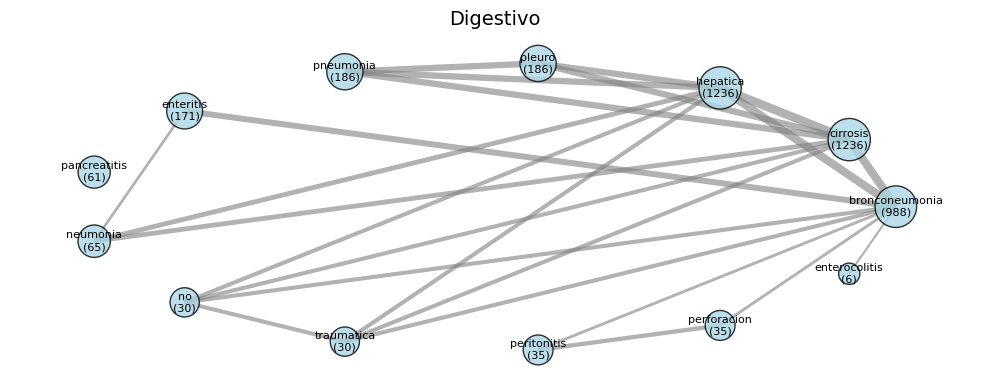

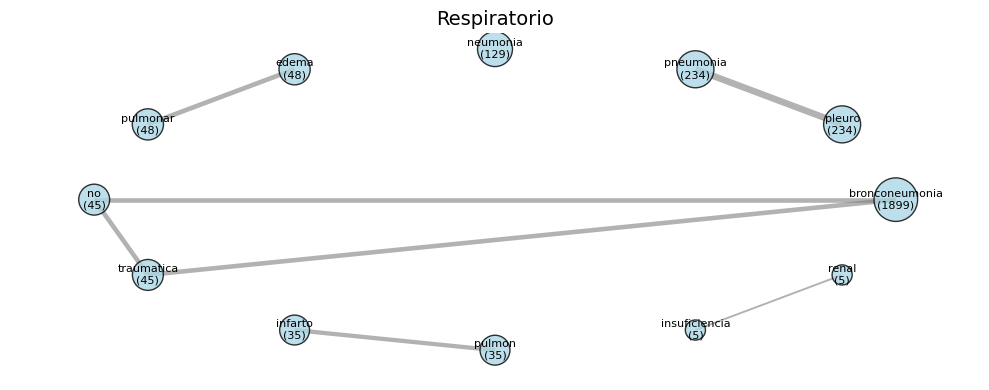

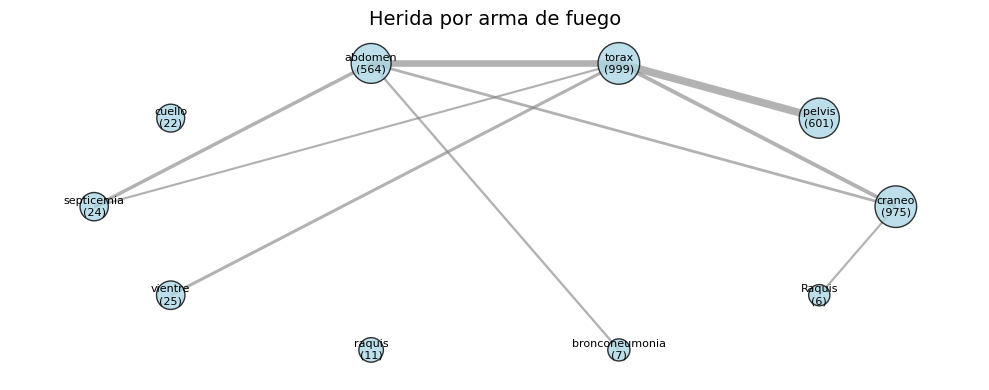

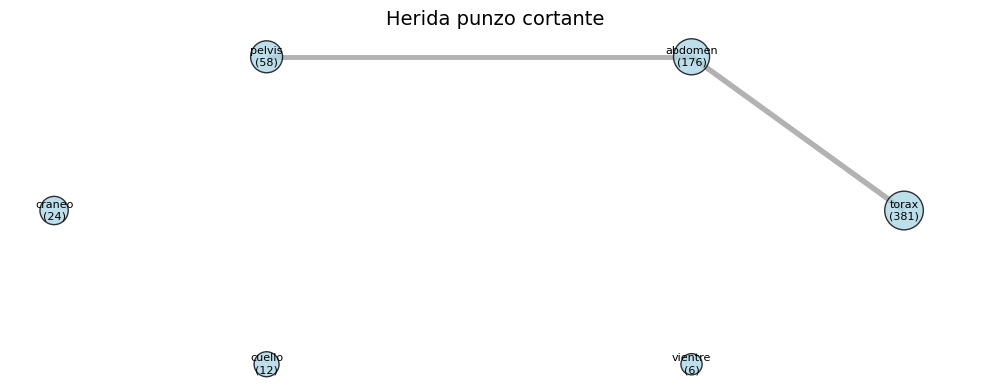

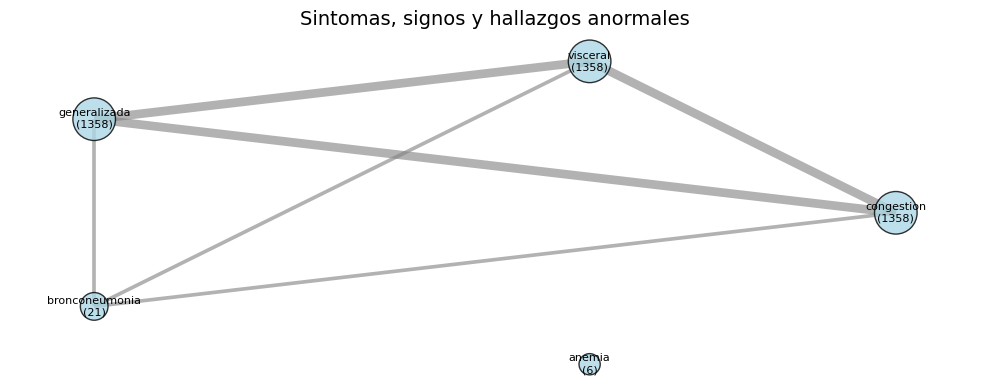

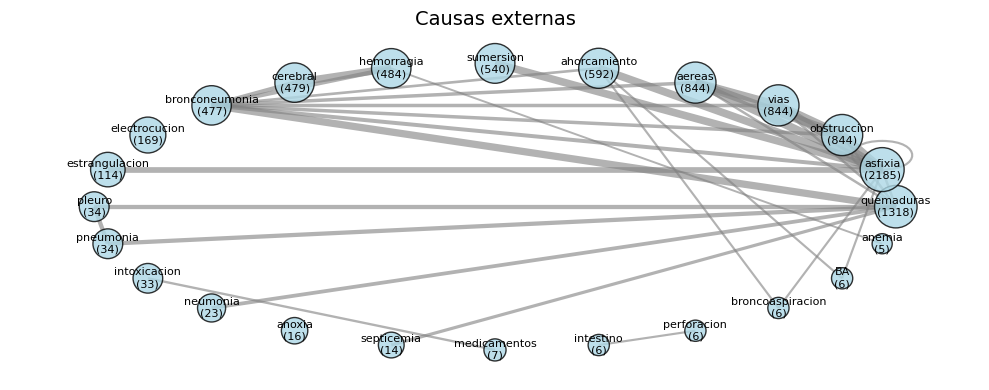

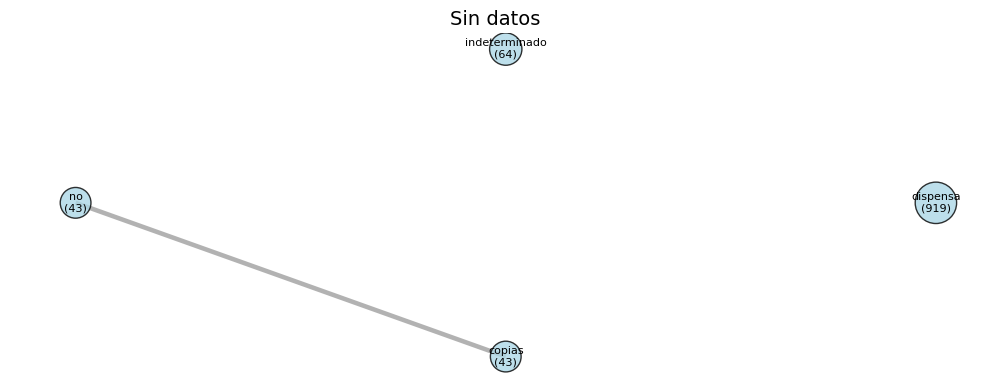

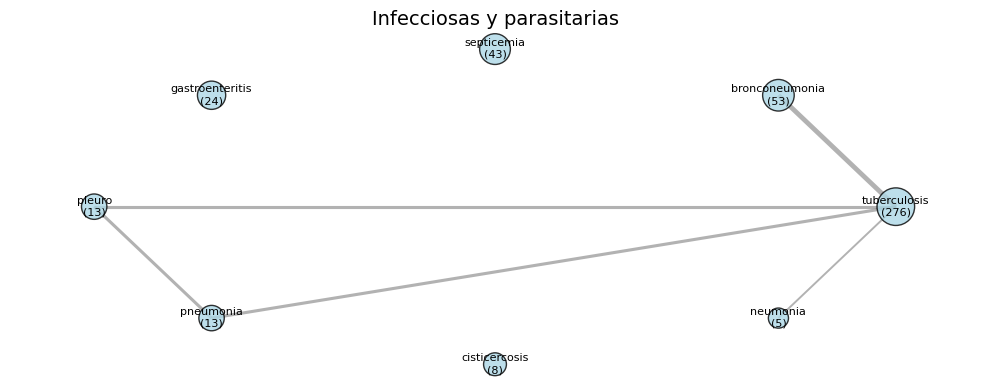

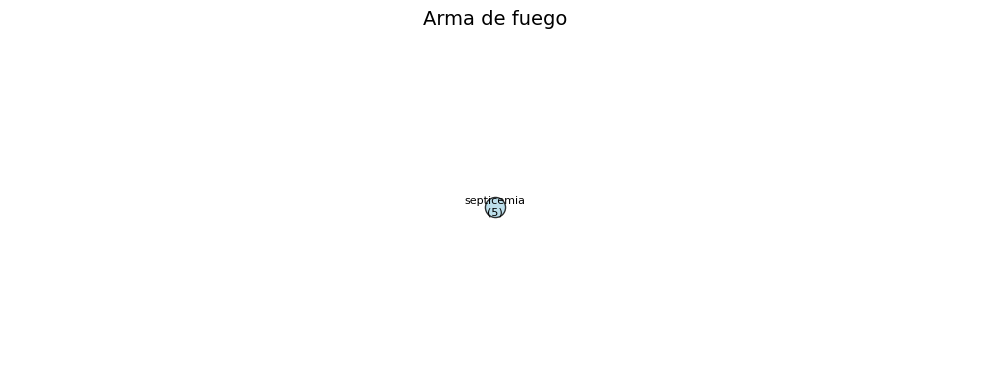

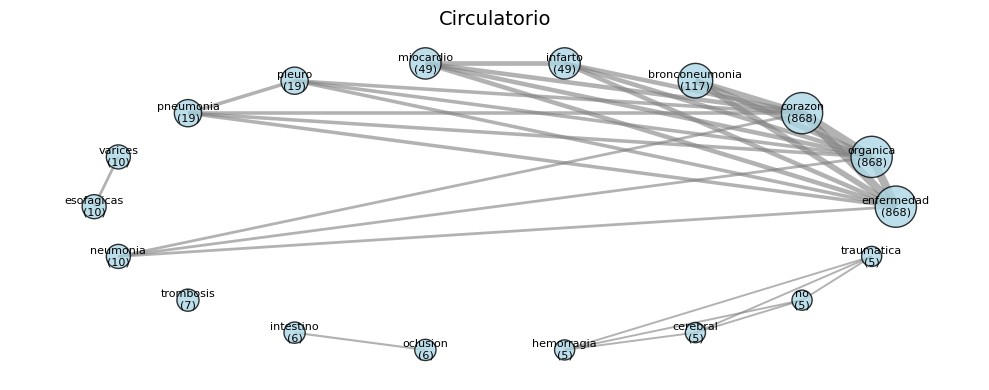

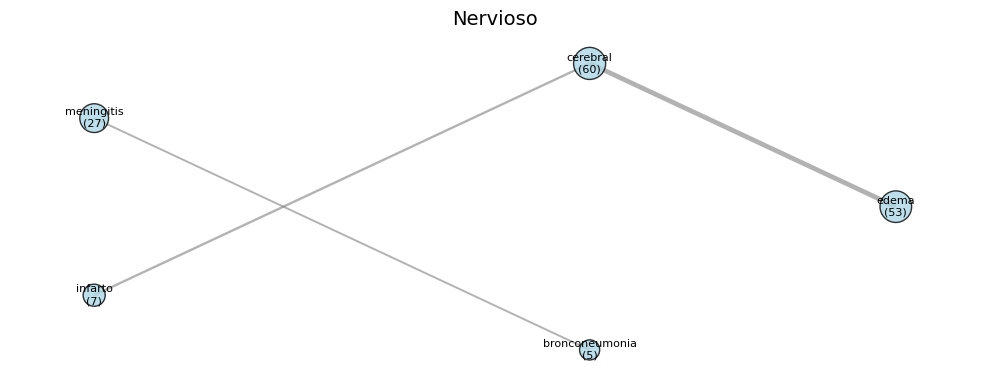

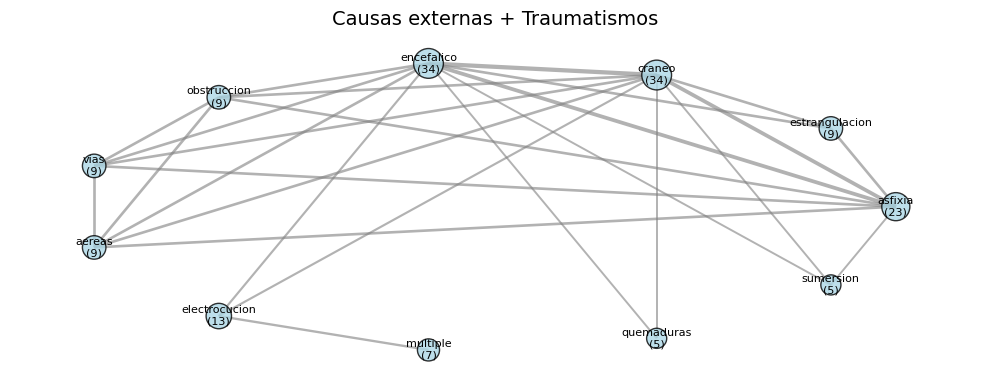

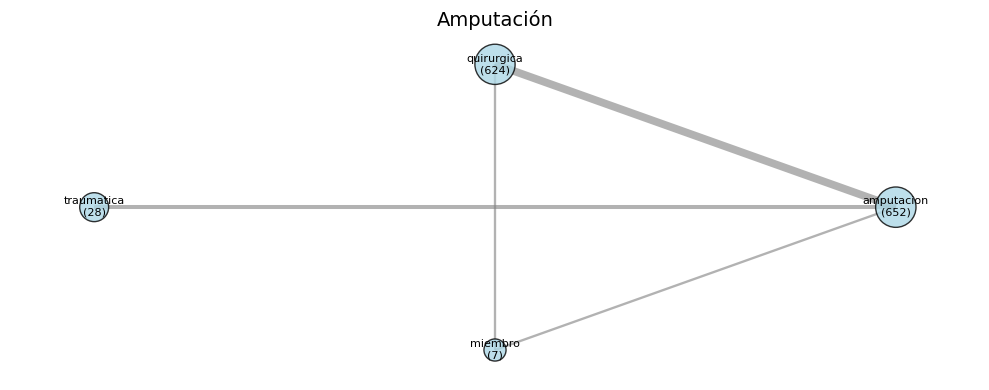

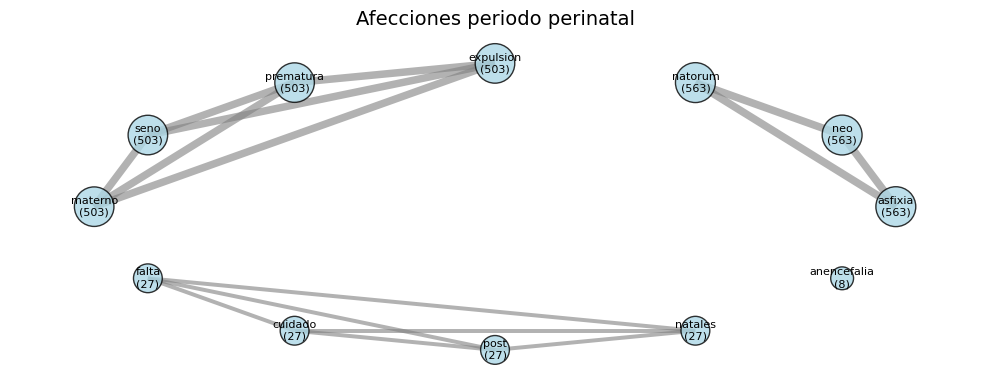

In [24]:
thr = 5
filtered = ['+','o','traumatismo','herida','arma','fuego','punzo','cortante','de','del','por',]

for clas in df_diag['Diagnostico_clasificacion'].unique():
    data = df_diag.loc[df_diag['Diagnostico_clasificacion']==clas,'Diagnostico_extendido'].value_counts()
    data = data[data>=thr]
    G = create_network_from_lists(data.index.to_list(), data.to_list(), remove_list=filtered, filter_singletons=False, sep=' ')
    
    # Obtain log10 of weight
    for node in G.nodes():
        G.nodes[node]["weight_log10"] = float(np.log10( G.nodes[node]["weight"] ))
    for node1, node2 in G.edges():
        G.edges[node1, node2]["weight_log10"] = float(np.log10( G.edges[node1, node2]["weight"] ))
    
    # Plot the graph
    plot_weighted_graph(
                        G, plot_title=clas, 
                        figsize=(10,4), font_size=8, layout='circular',
                        node_size_attribute='weight_log10', edge_width_attribute='weight_log10',
                        node_label_attribute='weight')


### Análisis especiales con todos los datos

Fetos
Menores de 1 año
Infecciosas
Causa sexo 
Causas edad


**Done**